In [1]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("dataset.csv")

print(df.head())

   Student_ID    Name  Math  Science  English  Attendance
0         101   Aarav    85       78       90          92
1         102    Riya    92       88       95          96
2         103   Rohan    65       70       68          75
3         104  Simran    78       82       80          88
4         105  Ananya    95       91       94          98


In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (10, 6)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Student_ID  10 non-null     int64
 1   Name        10 non-null     str  
 2   Math        10 non-null     int64
 3   Science     10 non-null     int64
 4   English     10 non-null     int64
 5   Attendance  10 non-null     int64
dtypes: int64(5), str(1)
memory usage: 663.0 bytes


In [5]:
# Check missing values

print("Missing Values:")

print(df.isnull().sum())

Missing Values:
Student_ID    0
Name          0
Math          0
Science       0
English       0
Attendance    0
dtype: int64


In [6]:
# Check duplicate records

print("Duplicate Records:")

print(df.duplicated().sum())

Duplicate Records:
0


In [7]:
# Remove duplicate records

df = df.drop_duplicates()

# Check missing values again

print(df.isnull().sum())

print("Data Cleaning Completed!")

Student_ID    0
Name          0
Math          0
Science       0
English       0
Attendance    0
dtype: int64
Data Cleaning Completed!


In [8]:
# Calculate total marks

df["Total_Marks"] = (
    df["Math"] +
    df["Science"] +
    df["English"]
)

# Calculate average marks

df["Average_Marks"] = df["Total_Marks"] / 3

print(df)

   Student_ID    Name  Math  Science  English  Attendance  Total_Marks  \
0         101   Aarav    85       78       90          92          253   
1         102    Riya    92       88       95          96          275   
2         103   Rohan    65       70       68          75          203   
3         104  Simran    78       82       80          88          240   
4         105  Ananya    95       91       94          98          280   
5         106   Karan    45       55       50          60          150   
6         107    Neha    88       85       90          94          263   
7         108   Arjun    72       68       75          80          215   
8         109   Priya    55       60       58          70          173   
9         110  Aditya    81       79       84          89          244   

   Average_Marks  
0      84.333333  
1      91.666667  
2      67.666667  
3      80.000000  
4      93.333333  
5      50.000000  
6      87.666667  
7      71.666667  
8      57.6666

In [9]:
# Categorize student performance

def performance_category(marks):
    if marks >= 80:
        return "Excellent"
    elif marks >= 60:
        return "Good"
    elif marks >= 40:
        return "Average"
    else:
        return "Needs Improvement"

df["Performance"] = df["Average_Marks"].apply(performance_category)

print(df[["Name", "Average_Marks", "Performance"]])

     Name  Average_Marks Performance
0   Aarav      84.333333   Excellent
1    Riya      91.666667   Excellent
2   Rohan      67.666667        Good
3  Simran      80.000000   Excellent
4  Ananya      93.333333   Excellent
5   Karan      50.000000     Average
6    Neha      87.666667   Excellent
7   Arjun      71.666667        Good
8   Priya      57.666667     Average
9  Aditya      81.333333   Excellent


In [10]:
# Check student pass or fail

df["Result"] = np.where(
    (df["Math"] >= 40) &
    (df["Science"] >= 40) &
    (df["English"] >= 40) &
    (df["Attendance"] >= 75),
    "Pass",
    "Fail"
)

print(df[["Name", "Attendance", "Average_Marks", "Result"]])

     Name  Attendance  Average_Marks Result
0   Aarav          92      84.333333   Pass
1    Riya          96      91.666667   Pass
2   Rohan          75      67.666667   Pass
3  Simran          88      80.000000   Pass
4  Ananya          98      93.333333   Pass
5   Karan          60      50.000000   Fail
6    Neha          94      87.666667   Pass
7   Arjun          80      71.666667   Pass
8   Priya          70      57.666667   Fail
9  Aditya          89      81.333333   Pass


In [11]:
# Sort students by average marks

top_students = df.sort_values(
    by="Average_Marks",
    ascending=False
)

print("Top Performing Students:")

print(top_students[["Name", "Average_Marks"]].head(5))

Top Performing Students:
     Name  Average_Marks
4  Ananya      93.333333
1    Riya      91.666667
6    Neha      87.666667
0   Aarav      84.333333
9  Aditya      81.333333


In [12]:
print("Class Average Marks:", df["Average_Marks"].mean())

print("Highest Average:", df["Average_Marks"].max())

print("Lowest Average:", df["Average_Marks"].min())

print("Total Students:", len(df))

Class Average Marks: 76.53333333333333
Highest Average: 93.33333333333333
Lowest Average: 50.0
Total Students: 10


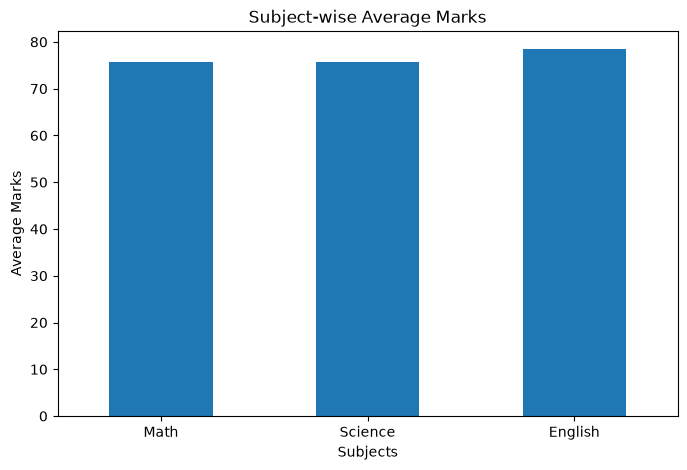

In [13]:
# Calculate average marks of each subject

subject_avg = df[["Math", "Science", "English"]].mean()

# Create bar chart

plt.figure(figsize=(8, 5))

subject_avg.plot(kind="bar")

plt.title("Subject-wise Average Marks")
plt.xlabel("Subjects")
plt.ylabel("Average Marks")

plt.xticks(rotation=0)
plt.savefig("screenshots/graph1.png", dpi=300, bbox_inches="tight")

plt.show()

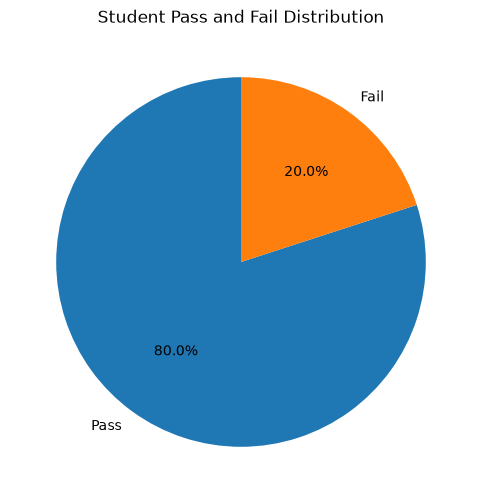

In [14]:
# Count pass and fail students

result_count = df["Result"].value_counts()

# Create pie chart

plt.figure(figsize=(6, 6))

plt.pie(
    result_count,
    labels=result_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Student Pass and Fail Distribution")
plt.savefig("screenshots/graph2.png", dpi=300, bbox_inches="tight")

plt.show()

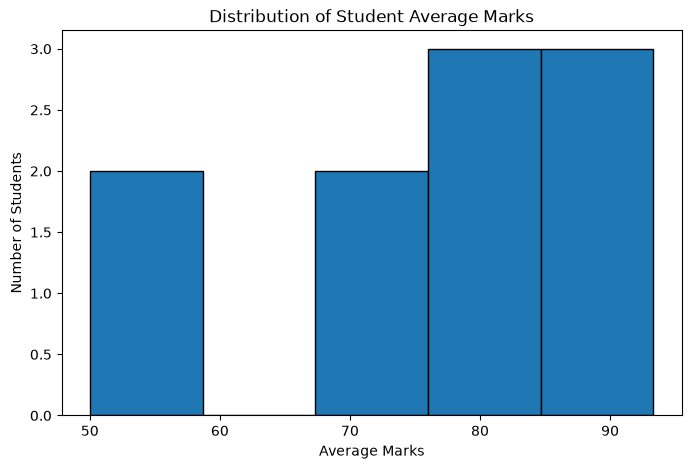

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["Average_Marks"],
    bins=5,
    edgecolor="black"
)

plt.title("Distribution of Student Average Marks")
plt.xlabel("Average Marks")
plt.ylabel("Number of Students")
plt.savefig("screenshots/graph3.png", dpi=300, bbox_inches="tight")

plt.show()

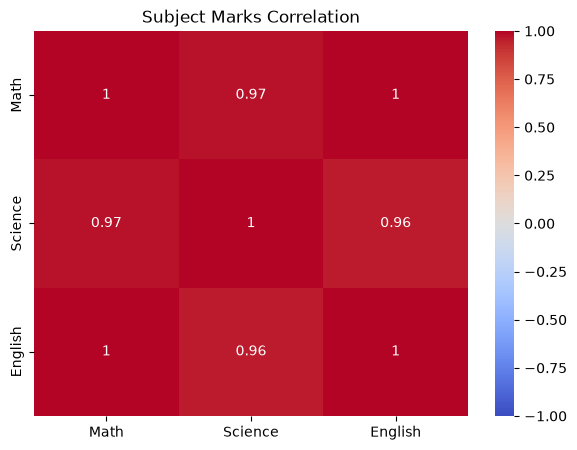

In [16]:
# Calculate correlation

correlation = df[["Math", "Science", "English"]].corr()

# Create heatmap

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Subject Marks Correlation")
plt.savefig("screenshots/graph4.png", dpi=300, bbox_inches="tight")

plt.show()

In [17]:
import pandas as pd

df = pd.read_csv("student_data/student-mat.txt", sep=";")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [18]:
# Check all column names
print("Dataset Columns:")
print(df.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Check dataset information
df.info()

Dataset Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Missing Values:
0

Duplicate Rows:
0
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian   

In [19]:
# Check final grade distribution
print(df["G3"].describe())

# Create Pass/Fail column
df["Result"] = df["G3"].apply(
    lambda marks: "Pass" if marks >= 10 else "Fail"
)

# Count Pass and Fail students
print("\nStudent Result Distribution:")
print(df["Result"].value_counts())

# Display first 10 records
df[["G3", "Result"]].head(10)

count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

Student Result Distribution:
Result
Pass    265
Fail    130
Name: count, dtype: int64


,G3,Result
0,6,Fail
1,6,Fail
2,10,Pass
3,15,Pass
4,10,Pass
5,15,Pass
6,11,Pass
7,6,Fail
8,19,Pass
9,15,Pass


In [20]:
# Select input features
X = df[[
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2",
    "age",
    "health",
    "freetime"
]]

# Select target variable
y = df["Result"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features:
   studytime  failures  absences  G1  G2  age  health  freetime
0          2         0         6   5   6   18       3         3
1          2         0         4   5   5   17       3         3
2          2         3        10   7   8   15       3         3
3          3         0         2  15  14   15       5         2
4          2         0         4   6  10   16       5         3

Target Variable:
0    Fail
1    Fail
2    Pass
3    Pass
4    Pass
Name: Result, dtype: str

Features Shape: (395, 8)
Target Shape: (395,)


In [21]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Data: (316, 8)
Testing Data: (79, 8)
Training Labels: (316,)
Testing Labels: (79,)


In [22]:
from sklearn.tree import DecisionTreeClassifier

# Create Machine Learning model
model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Machine Learning Model Trained Successfully!")

Machine Learning Model Trained Successfully!


In [23]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Predict results using testing data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 87.34 %

Confusion Matrix:
[[23  3]
 [ 7 46]]

Classification Report:
              precision    recall  f1-score   support

        Fail       0.77      0.88      0.82        26
        Pass       0.94      0.87      0.90        53

    accuracy                           0.87        79
   macro avg       0.85      0.88      0.86        79
weighted avg       0.88      0.87      0.88        79



In [24]:
import joblib

# Save trained ML model
joblib.dump(model, "student_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [25]:
# Select one student from testing data
student = X_test.iloc[[0]]

# Predict student's result
prediction = model.predict(student)

print("Student Details:")
print(student)

print("\nPredicted Result:", prediction[0])
print("Actual Result:", y_test.iloc[0])

Student Details:
     studytime  failures  absences  G1  G2  age  health  freetime
305          2         1         8  14  12   18       3         4

Predicted Result: Pass
Actual Result: Pass


In [26]:
import os

print("File exists:", os.path.exists("student_model.pkl"))

if os.path.exists("student_model.pkl"):
    print("File size:", os.path.getsize("student_model.pkl"), "bytes")

File exists: True
File size: 3897 bytes


In [27]:
import joblib
import os

# Save trained model
joblib.dump(model, "student_model.pkl")

# Check file size
print("File size:", os.path.getsize("student_model.pkl"), "bytes")
print("Model saved successfully!")

File size: 3897 bytes
Model saved successfully!
